In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import glob


import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))



/kaggle/input/datasets/mervebzn/ps4-vs-xbox-one/XboxOne_GameSales.csv
/kaggle/input/datasets/mervebzn/ps4-vs-xbox-one/PS4_GamesSales.csv
/kaggle/input/datasets/mervebzn/video-games-sales/Video_Games_Sales_as_at_22_Dec_2016.csv


In [3]:
df = pd.read_csv('/kaggle/input/datasets/mervebzn/video-games-sales/Video_Games_Sales_as_at_22_Dec_2016.csv')
df_raw = df.copy()
df.head()

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8.0,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8.0,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


# Understanding the data

In [4]:
df.shape

(16719, 16)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  object 
 1   Platform         16719 non-null  object 
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  object 
 4   Publisher        16665 non-null  object 
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       7590 non-null   float64
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  object 
 15  Rating           9950 non-null   object 
dtypes: float64(10), object(6)
memory usage: 2.0+ MB


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year_of_Release,16450.0,2006.487356,5.878995,1980.00,2003.00,2007.00,2010.00,2020.00
NA_Sales,16719.0,0.263330,0.813514,0.00,0.00,0.08,0.24,41.36
EU_Sales,16719.0,0.145025,0.503283,0.00,0.00,0.02,0.11,28.96
JP_Sales,16719.0,0.077602,0.308818,0.00,0.00,0.00,0.04,10.22
Other_Sales,16719.0,0.047332,0.186710,0.00,0.00,0.01,0.03,10.57
Global_Sales,16719.0,0.533543,1.547935,0.01,0.06,0.17,0.47,82.53
Critic_Score,8137.0,68.967679,13.938165,13.00,60.00,71.00,79.00,98.00
Critic_Count,8137.0,26.360821,18.980495,3.00,12.00,21.00,36.00,113.00
User_Score,7590.0,7.125046,1.500006,0.00,6.40,7.50,8.20,9.70
User_Count,7590.0,162.229908,561.282326,4.00,10.00,24.00,81.00,10665.00


# Data Quality 

In [7]:
# Missing values
missing = df.isna().sum().to_frame('missing')
missing['pct'] = (missing['missing']/ len(df) * 100).round(1)
print(missing[missing['missing'] > 0].sort_values('missing', ascending=False))

                 missing   pct
User_Score          9129  54.6
User_Count          9129  54.6
Critic_Count        8582  51.3
Critic_Score        8582  51.3
Rating              6769  40.5
Developer           6623  39.6
Year_of_Release      269   1.6
Publisher             54   0.3
Name                   2   0.0
Genre                  2   0.0


In [8]:
# Duplicates
print('Full-row duplicates:', df.duplicated().sum())
print('Name & Platform & Year of release', df.duplicated(["Name", "Platform", "Year_of_Release"]).sum())
df[df.duplicated(["Name", "Platform", "Year_of_Release"], keep=False)]

Full-row duplicates: 0
Name & Platform & Year of release 2


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
604,Madden NFL 13,PS3,2012.0,Sports,Electronic Arts,2.11,0.22,0.00,0.23,2.56,83.0,22.0,5.5,101.0,EA Tiburon,E
659,NaN,GEN,1993.0,NaN,Acclaim Entertainment,1.78,0.53,0.00,0.08,2.39,NaN,NaN,NaN,NaN,NaN,NaN
14246,NaN,GEN,1993.0,NaN,Acclaim Entertainment,0.00,0.00,0.03,0.00,0.03,NaN,NaN,NaN,NaN,NaN,NaN
16233,Madden NFL 13,PS3,2012.0,Sports,Electronic Arts,0.00,0.01,0.00,0.00,0.01,83.0,22.0,5.5,101.0,EA Tiburon,E


In [9]:
# Invalid years 
df['Year_of_Release'].value_counts().sort_index().tail(8)

Year_of_Release
2011.0    1136
2012.0     653
2013.0     544
2014.0     581
2015.0     606
2016.0     502
2017.0       3
2020.0       1
Name: count, dtype: int64

In [10]:
# Dtype Check
df['User_Score'].dtype, df['User_Score'].unique()[:10]

(dtype('float64'), array([8. , nan, 8.3, 8.5, 6.6, 8.4, 8.6, 7.7, 6.3, 7.4]))

# Data Cleaning

In [11]:
# Invalid rows
n0 = len(df)

df= df.dropna(subset=['Name'])

In [12]:
df = df[df['Year_of_Release'].isna() | (df['Year_of_Release']<= 2016)]

In [13]:
print(f'Rows removed {n0 - len(df)}')

Rows removed 6


In [14]:
# Merge Duplicates
key = ["Name", "Platform", "Year_of_Release"]
sales_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]

print('Duplicate before : ', df.duplicated(key).sum())

agg = {c: 'sum' for c in sales_cols}
agg.update({c: 'first' for c in df.columns if c not in key + sales_cols})
df= df.groupby(key, as_index= False, dropna= False).agg(agg)

print('Duplicate after : ', df.duplicated(key).sum())

Duplicate before :  1
Duplicate after :  0


In [15]:
for c in ["Publisher", "Developer", "Rating"]:
    df[c] =df[c].fillna('Unknown')

df['Rating']= df['Rating'].replace({"K-A": "E", "RP": "Unknown"})

df['Has_Score'] = np.where(df['Critic_Score'].notna() | df['User_Score'].notna(), 'Scored','Unknown')



In [16]:
# Data type
df['User_Score'] = pd.to_numeric(df['User_Score'], errors='coerce')

for c in ["Year_of_Release", "Critic_Score", "Critic_Count", "User_Count"]:
    df[c] = df[c].astype('Int64')

df['User_Score_100'] = df['User_Score'] * 10

df = df.rename(columns= {"Year_of_Release": "Year"})

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16712 entries, 0 to 16711
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Name            16712 non-null  object 
 1   Platform        16712 non-null  object 
 2   Year            16443 non-null  Int64  
 3   NA_Sales        16712 non-null  float64
 4   EU_Sales        16712 non-null  float64
 5   JP_Sales        16712 non-null  float64
 6   Other_Sales     16712 non-null  float64
 7   Global_Sales    16712 non-null  float64
 8   Genre           16712 non-null  object 
 9   Publisher       16712 non-null  object 
 10  Critic_Score    8136 non-null   Int64  
 11  Critic_Count    8136 non-null   Int64  
 12  User_Score      7589 non-null   float64
 13  User_Count      7589 non-null   Int64  
 14  Developer       16712 non-null  object 
 15  Rating          16712 non-null  object 
 16  Has_Score       16712 non-null  object 
 17  User_Score_100  7589 non-null  

In [17]:
print(df.shape)
print(df.isna().sum()[df.isna().sum() > 0])
print(df['Year'].min(), '-', df['Year'].max())
print(round(df['Global_Sales'].sum(),1 ))

(16712, 18)
Year               269
Critic_Score      8576
Critic_Count      8576
User_Score        9123
User_Count        9123
User_Score_100    9123
dtype: int64
1980 - 2016
8917.5


In [18]:
df.to_csv("video_games_clean.csv", index=False)

# EDA


In [19]:
# Overall Summary
print('Total recodrs (releases):', len(df))
print('Unique  games: ', df['Name'].nunique())
print('Total Sales (millions):', round(df['Global_Sales'].sum(), 1))
print('Year range:', df['Year'].min(), '-', df['Year'].max())

Total recodrs (releases): 16712
Unique  games:  11559
Total Sales (millions): 8917.5
Year range: 1980 - 2016


In [20]:
# Most common genres
genre_summary = (df.groupby('Genre')
                .agg(Releases =('Name', 'count'),
                    Total_Sales=('Global_Sales', 'sum'),
                    Avg_Sales=('Global_Sales', 'mean'),
                    Median_Sales=("Global_Sales", "median"))
                .round(2)
                .sort_values('Releases', ascending= False)
                )

genre_summary

,Releases,Total_Sales,Avg_Sales,Median_Sales
Genre,,,,
Action,3369,1745.26,0.52,0.19
Sports,2347,1332.00,0.57,0.22
Misc,1750,803.18,0.46,0.16
Role-Playing,1498,934.35,0.62,0.18
Shooter,1323,1052.94,0.80,0.23
Adventure,1303,237.69,0.18,0.05
Racing,1249,728.90,0.58,0.19
Platform,888,828.08,0.93,0.27
Simulation,873,390.13,0.45,0.15


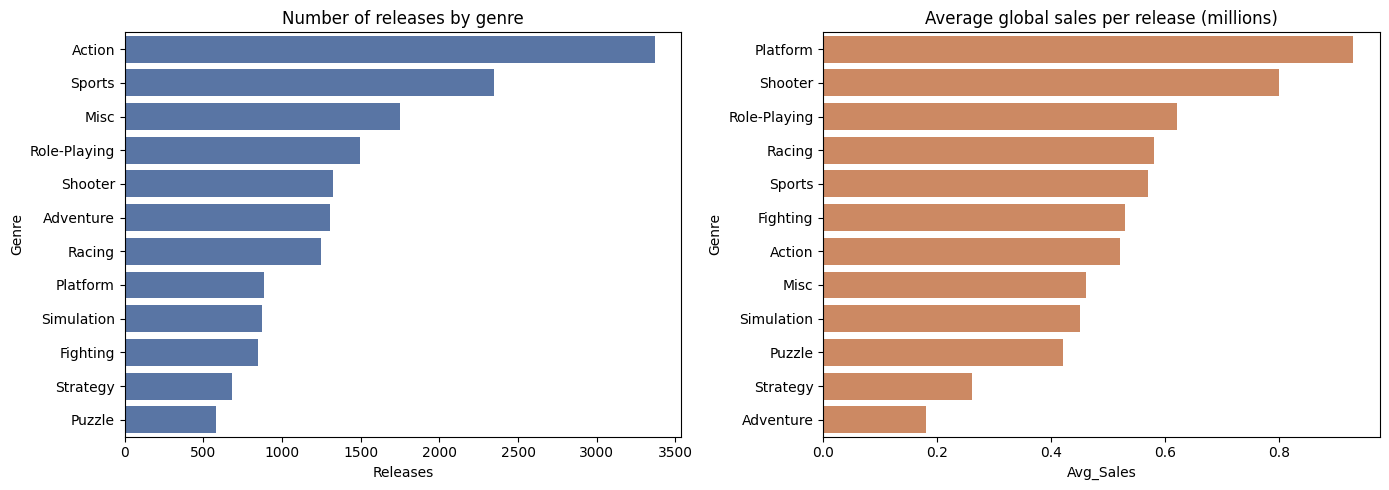

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data= genre_summary.reset_index(), y='Genre', x='Releases',
           color='#4C72B0', ax=ax[0])
ax[0].set_title('Number of releases by genre')

by_avg = genre_summary.sort_values('Avg_Sales', ascending=False).reset_index()
sns.barplot(data=by_avg, y='Genre', x='Avg_Sales', color='#DD8452', ax=ax[1])
ax[1].set_title('Average global sales per release (millions)')

plt.tight_layout()

plt.savefig('genre_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

**Insight:** Action is the most common genre (3,369 releases) and has the highest total sales (1,745M), so it is the biggest market, but also the most crowded: it earns only 0.52M per release. Platform (0.93M) and Shooter (0.80M) earn the most per release and stay in the top 2 even when using the median. Half of Platform sales come from Nintendo, while Shooter sales are spread across many titles, which makes Shooter the safer bet.

**Recommendation:** Prioritize Shooter (and Platform only with a strong IP); keep Action for volume, but with fewer, higher-quality releases.

In [22]:
# Top platforms by sales
platform_summary = (df.groupby('Platform')
                   .agg(Releases=('Name', 'count'),
                       Total_Sales=('Global_Sales', 'sum'),
                       Avg_Sales=('Global_Sales', 'mean'),
                       Median_Sales=("Global_Sales", "median"))
                    .round(2)
                    .sort_values('Total_Sales', ascending= False)
                   )
platform_summary['Share_%'] =(platform_summary['Total_Sales']
                              /df['Global_Sales'].sum() * 100).round(1)

platform_summary.head(10)

,Releases,Total_Sales,Avg_Sales,Median_Sales,Share_%
Platform,,,,,
PS2,2161,1255.64,0.58,0.23,14.1
X360,1262,971.63,0.77,0.28,10.9
PS3,1330,939.43,0.71,0.27,10.5
Wii,1320,908.13,0.69,0.19,10.2
DS,2151,806.81,0.38,0.11,9.0
PS,1197,730.68,0.61,0.26,8.2
GBA,822,318.50,0.39,0.16,3.6
PS4,392,314.19,0.80,0.20,3.5
PSP,1209,294.30,0.24,0.09,3.3


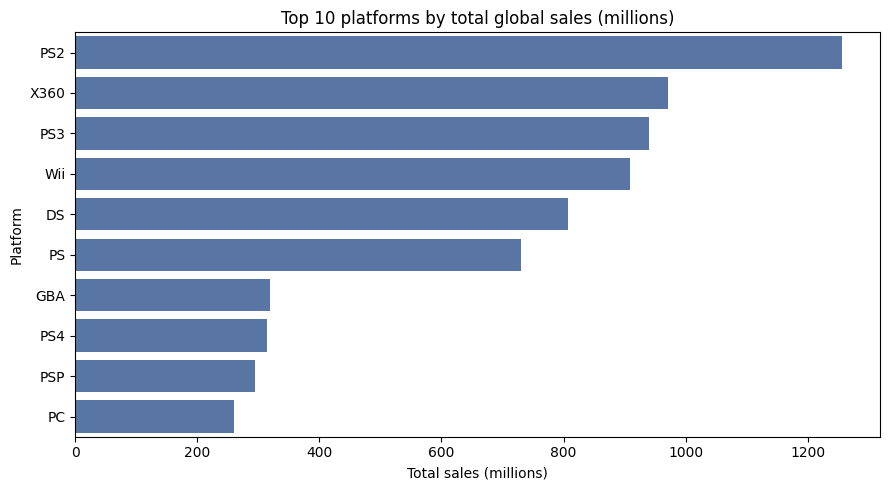

In [45]:
top_platforms =platform_summary.head(10).reset_index()

plt.figure(figsize=(9,5))
sns.barplot(data= top_platforms, y='Platform', x='Total_Sales', color='#4C72B0')
plt.title('Top 10 platforms by total global sales (millions)')
plt.xlabel('Total sales (millions)')
plt.tight_layout()

plt.savefig('top_10_platforms.png', dpi=300, bbox_inches='tight')

plt.show()

**Insight:** PS2 (1,256M) and X360 (972M) lead in total sales, with PS3 close behind. Per release, PS4 stands out (0.80M, second among platforms with 100+ releases) even though it launched in 2013 and the data ends in 2016, so its sales are still incomplete. X360 combines high total sales with high sales per release (0.77M). PS2 and X360 are previous-generation platforms, so they show what a successful platform looks like rather than where to invest today.

**Recommendation:** Focus on current-generation platforms (PS4, Xbox One); PS4 already shows strong per-release returns.

In [24]:
# Top publishers
publisher_summary = (df[df['Publisher'] != 'Unknown']
                    .groupby('Publisher')
                     .agg(Releases=('Name', 'count'),
                         Total_Sales=('Global_Sales', 'sum'),
                         Avg_Sales=('Global_Sales', 'mean'),
                         Median_Sales=("Global_Sales", "median"))
                    .round(2)
                     .sort_values('Total_Sales', ascending= False)
                    )
publisher_summary.head(10)

,Releases,Total_Sales,Avg_Sales,Median_Sales
Publisher,,,,
Nintendo,706,1788.81,2.53,0.89
Electronic Arts,1355,1116.96,0.82,0.47
Activision,985,731.16,0.74,0.28
Sony Computer Entertainment,687,606.48,0.88,0.33
Ubisoft,932,471.32,0.51,0.20
Take-Two Interactive,422,403.82,0.96,0.30
THQ,715,338.44,0.47,0.26
Konami Digital Entertainment,834,282.39,0.34,0.15
Sega,636,270.30,0.43,0.19


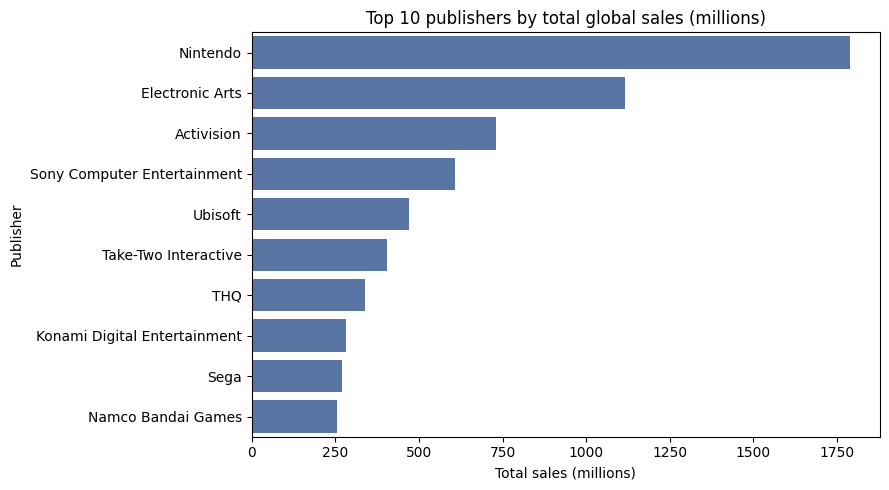

In [46]:
top_pub = publisher_summary.head(10).reset_index()

plt.figure(figsize =(9,5))
sns.barplot(data=top_pub, y='Publisher', x='Total_Sales', color='#4C72B0')
plt.title('Top 10 publishers by total global sales (millions)')
plt.xlabel('Total sales (millions)')
plt.tight_layout()

plt.savefig('top_10_publishers.png', dpi=300, bbox_inches='tight')
plt.show()

**Insight :** Nintendo leads on every measure: highest total sales (1,789M), highest average (2.53M) and highest median (0.89M) per release, with only 706 releases, so it wins on quality, not quantity. Electronic Arts is second in total sales and the most consistent among large publishers (highest median, 0.47M). Take-Two ranks sixth in total sales but second in average per release (0.96M); however, about 40% of its sales come from Grand Theft Auto, so it depends on a few hits.

**Recommendation:** Learn from Nintendo's strategy (few strong franchises), EA's consistent catalog and Take-Two's flagship-title model; avoid depending on a single hit.

In [26]:
# Best-selling games
df.nlargest(10, 'Global_Sales')[['Name', 'Platform', 'Year', 'Genre', 'Publisher']]

top_games = (df.groupby('Name')
             .agg(Global_Sales=('Global_Sales', 'sum'),
                 Plarforms=('Platform', 'nunique'),
                 Genre=('Genre', 'first'),
                 Publisher=('Publisher', 'first'))
             .sort_values('Global_Sales', ascending= False)
             .head(10)
)

top_games.round(2)

,Global_Sales,Plarforms,Genre,Publisher
Name,,,,
Wii Sports,82.53,1,Sports,Nintendo
Grand Theft Auto V,56.57,5,Action,Take-Two Interactive
Super Mario Bros.,45.31,2,Platform,Nintendo
Tetris,35.84,2,Puzzle,Nintendo
Mario Kart Wii,35.52,1,Racing,Nintendo
Wii Sports Resort,32.77,1,Sports,Nintendo
Pokemon Red/Pokemon Blue,31.37,1,Role-Playing,Nintendo
Call of Duty: Black Ops,30.82,5,Shooter,Activision
Call of Duty: Modern Warfare 3,30.59,4,Shooter,Activision


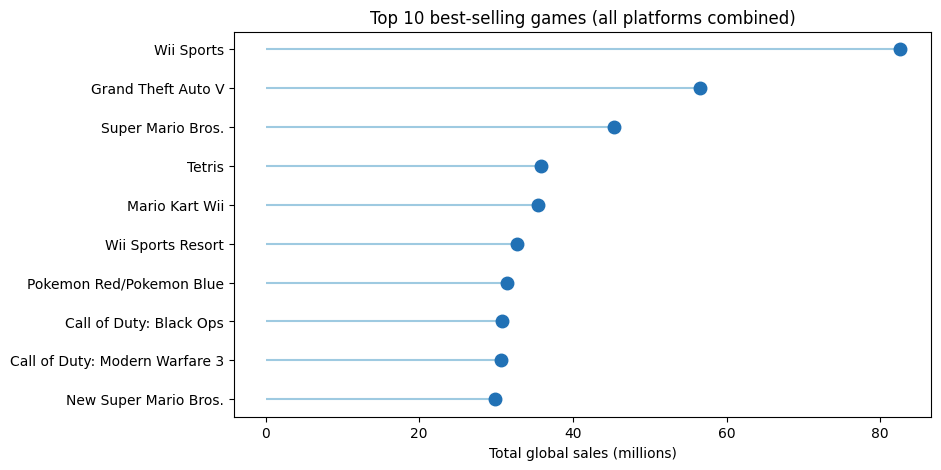

In [47]:
tg = top_games.sort_values('Global_Sales')

plt.figure(figsize=(9,5))
plt.hlines(y= tg.index, xmin=0, xmax=tg['Global_Sales'], color='#9ecae1')
plt.plot(tg['Global_Sales'], tg.index, 'o', color='#2171b5', markersize=9)
plt.xlabel('Total global sales (millions)')
plt.title('Top 10 best-selling games (all platforms combined)')

plt.savefig('top_10_games.png', dpi=300, bbox_inches='tight')

plt.show()

**Best-sellers:** Wii Sports (82.5M, one platform) is the best-selling game, followed by GTA V (56.6M across 5 platforms). Seven of the top 10 are Nintendo titles, mostly exclusive to its own consoles. Across all 11,559 titles, multi-platform games sell far more: titles on 4+ platforms average 3.60M (median 2.04M) versus 0.48M (median 0.12M) for single-platform titles. Only 24% of titles are multi-platform, yet they generate 53% of sales (publishers may port games that already sell well).

**Recommendation:** Release strong titles on multiple platforms; exclusivity pays off mainly when tied to your own hardware.

In [28]:
# Sales over the years
yearly= (df.dropna(subset=['Year'])
         .groupby('Year')
         .agg(Sales=('Global_Sales', 'sum'), Releases=('Name', 'count'))
         .reset_index()
)
yearly['Year']  = yearly['Year'].astype(int)
peak= yearly.loc[yearly['Sales'].idxmax()]

yearly

,Year,Sales,Releases
0,1980,11.38,9
1,1981,35.77,46
2,1982,28.86,36
3,1983,16.79,17
4,1984,50.36,14
5,1985,53.94,14
6,1986,37.07,21
7,1987,21.74,16
8,1988,47.22,15
9,1989,73.45,17


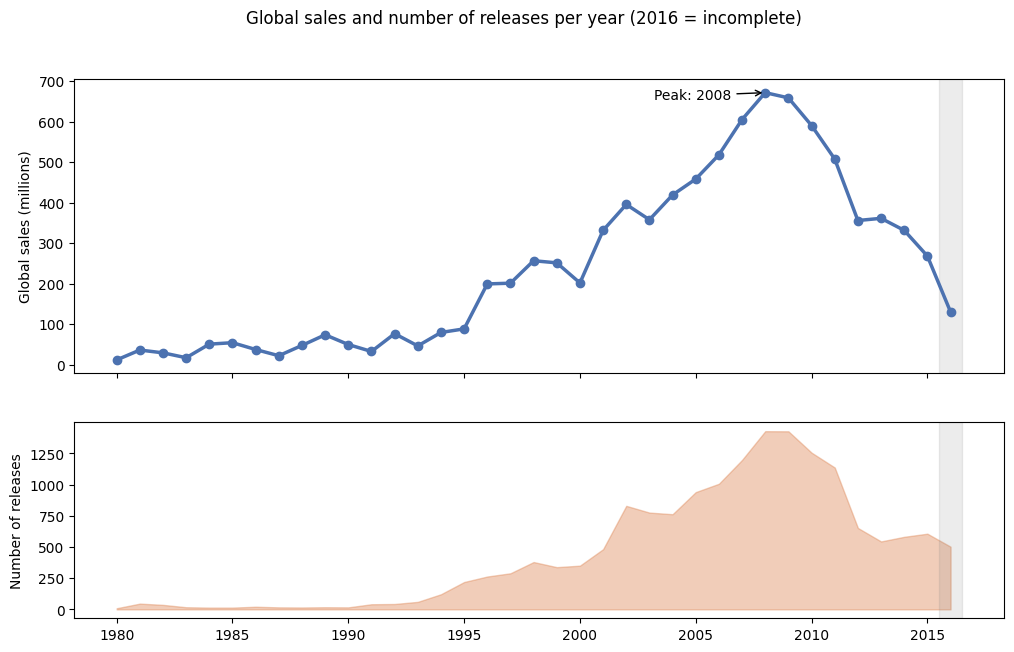

In [48]:
fig, ax =plt.subplots(2, 1, figsize=(12,7), sharex= True,
                      gridspec_kw={'height_ratios': [3,2]})
ax[0].plot(yearly['Year'], yearly['Sales'], marker='o', lw=2.5, color='#4C72B0')
ax[0].annotate(f'Peak: {int(peak['Year'])}', (peak['Year'], peak['Sales']),
              xytext=(-80,-5), textcoords='offset points',
                arrowprops= dict(arrowstyle='->'))
ax[0].set_ylabel('Global sales (millions)')
ax[1].fill_between(yearly['Year'], yearly['Releases'], alpha=0.4, color="#DD8452")
ax[1].set_ylabel('Number of releases')
for a in ax:
    a.axvspan(2015.5, 2016.5, color='gray', alpha=0.15)
fig.suptitle('Global sales and number of releases per year (2016 = incomplete)')

plt.savefig('yearly_sales_and_releases.png', dpi=300, bbox_inches='tight')
plt.show()

**Yearly trend:** Sales peaked in 2007–2009 (2008: 672M with 1,427 releases) and declined afterwards; 2016 is incomplete. Sales and release counts move together (r = 0.98), but this is partly mechanical. The key signal is that average sales per release fell as releases grew (r = -0.54; 0.64M in 1995–2000 vs 0.49M in 2005–2010): the market became crowded. Check the dataset description on Kaggle: if it tracks mainly physical retail, part of the decline may reflect the shift to digital.

**Recommendation:** Do not simply release more games; focus on fewer, higher-quality releases.


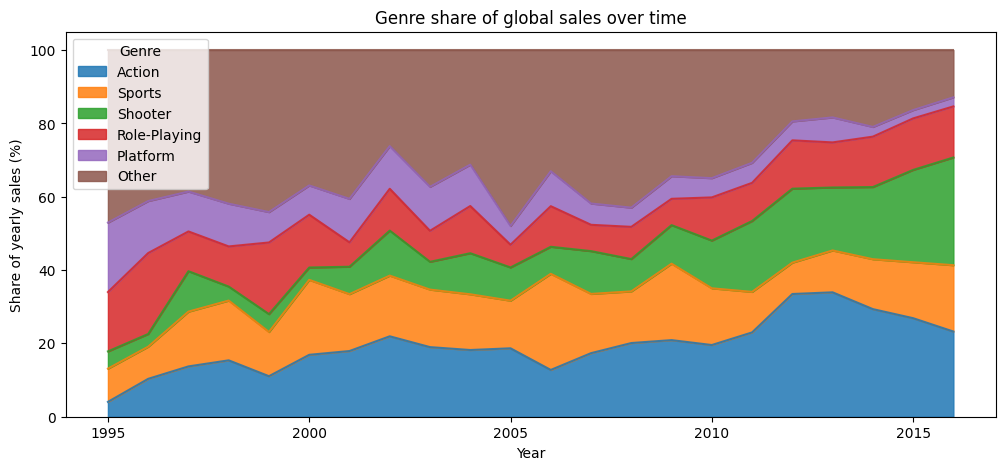

In [49]:
# Genre share over time
gy = (df.dropna(subset=['Year'])
      .pivot_table(index='Year', columns='Genre', values='Global_Sales',
                  aggfunc='sum', fill_value=0)    
)
gy.index = gy.index.astype(int)

top5 =gy.sum().nlargest(5).index
gy2 = gy[top5].copy()
gy2['Other'] = gy.drop(columns= top5).sum(axis=1)
gy2 = gy2.loc[1995:2016]

(gy2.div(gy2.sum(axis=1), axis=0) * 100).plot.area(figsize=(12,5), alpha=0.85)
plt.ylabel('Share of yearly sales (%)')
plt.title('Genre share of global sales over time')

plt.savefig('genre_share_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

**Genre share:** Action grew from 4% (1995) to 27% (2015) and Shooter from 5% to 25%; together they made up 52% of 2015 sales. Sports (15%) and Role-Playing (14%) stayed relatively stable, while Platform collapsed from 19% to 2%.

**Recommendation:** Prioritize Action and Shooter where demand is moving, keep Sports and RPG as a steady base, and treat Platform as a niche.

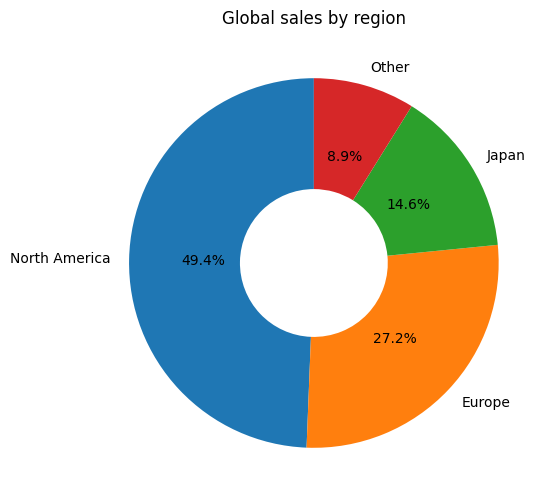

In [50]:
# Regions
rc= ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
reg = df[rc].sum()
reg.index = ["North America", "Europe", "Japan", "Other"]

reg.plot.pie(autopct ="%1.1f%%", startangle=90,
            wedgeprops= dict(width=0.6), figsize=(6,6))
plt.ylabel('')
plt.title('Global sales by region')

plt.savefig('global_sales_by_region.png', dpi=300, bbox_inches='tight')
plt.show()

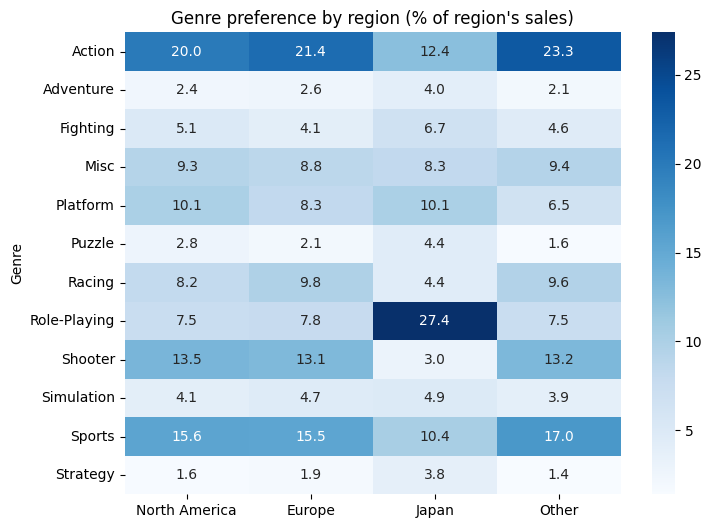

In [51]:
gr= df.groupby('Genre')[rc].sum()
gr_share = gr.div(gr.sum(axis=0), axis=1)*100
gr_share.columns = ["North America", "Europe", "Japan", "Other"]

plt.figure(figsize=(8,6))
sns.heatmap(gr_share.round(1), annot=True, fmt=".1f", cmap='Blues')
plt.title("Genre preference by region (% of region's sales)")

plt.savefig('genre_preference_by_region_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

**Regions:** North America generates 49.4% of global sales, Europe 27.2%, Japan 14.6% and the rest of the world 8.9%. Action and Sports dominate outside Japan, whereas in Japan Role-Playing leads with 27.4% (7.5–7.8% elsewhere) and Shooter is only 3.0% (about 13% elsewhere).

**Recommendation:** Use Action, Sports and Shooter for Western markets and an RPG-focused portfolio for Japan; localize rather than apply one global strategy.

scored games: 8136 of 16712


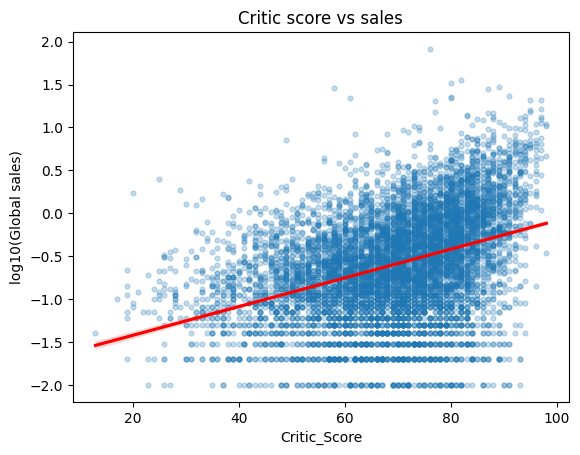

In [52]:
# Ratings vs sales
scored = df.dropna(subset=['Critic_Score']).copy()
scored['Critic_Score'] = scored['Critic_Score'].astype(float)
scored['User_Score_100'] = scored['User_Score_100'].astype(float)
scored['Log_Sales'] = np.log10(scored['Global_Sales'])

print('scored games:', len(scored), 'of', len(df))

sns.regplot(data=scored, x='Critic_Score', y='Log_Sales',
           scatter_kws= dict(alpha=0.25, s=12), line_kws= dict(color='red'))

plt.ylabel("log10(Global sales)")
plt.title("Critic score vs sales")
plt.savefig('critic_score_vs_sales.png', dpi=300, bbox_inches='tight')
            
plt.show()

In [34]:
# more robust for skewed data
scored[["Critic_Score", "User_Score_100", "Global_Sales"]].corr(method='spearman')

,Critic_Score,User_Score_100,Global_Sales
Critic_Score,1.000000,0.536502,0.394363
User_Score_100,0.536502,1.000000,0.156684
Global_Sales,0.394363,0.156684,1.000000


            count  mean  median
Score_Band                     
<50           802  0.23    0.12
50-59        1111  0.30    0.16
60-69        1849  0.37    0.18
70-79        2363  0.60    0.28
80-89        1678  1.22    0.59
90+           333  2.83    1.54


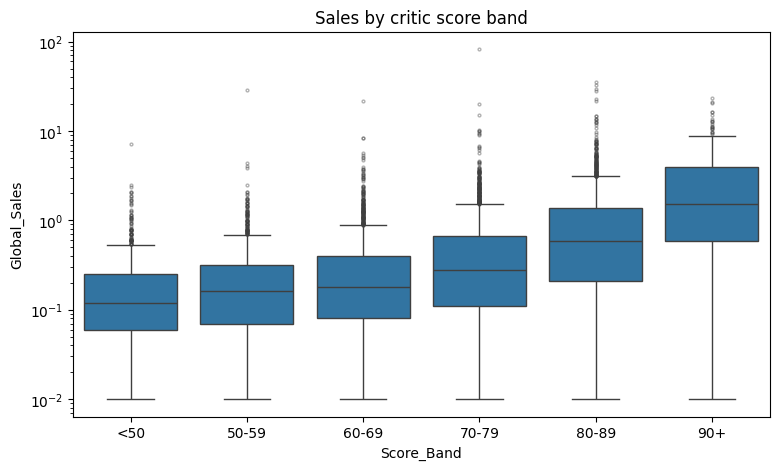

In [53]:
scored['Score_Band'] = pd.cut(scored['Critic_Score'],
                             bins= [0, 50, 60, 70, 80, 90, 101],
                             labels=["<50", "50-59", "60-69", "70-79", "80-89", "90+"], right=False)

print(scored.groupby('Score_Band', observed=True)['Global_Sales']
     .agg(['count', 'mean', 'median']).round(2))

plt.figure(figsize=(9,5))
sns.boxplot(data=scored, x='Score_Band', y='Global_Sales',
           flierprops= dict(markersize=2, alpha=0.4))
plt.yscale('log')
plt.title('Sales by critic score band')
plt.savefig('sales_by_critic_score_band.png', dpi=300, bbox_inches='tight')

plt.show()

**Ratings:** Sales rise steadily with critic score: median sales go from 0.12M (<50) to 1.54M (90+). Games scoring 80+ are 25% of scored games but 53% of scored sales; 90+ are only 4% of games but 17% of sales. The critic score correlates moderately with sales (Spearman 0.39), the user score only weakly (0.16). Caveats: only 49% of games have scores (and they are more popular ones), correlation is not causation, and scores are known only after release.

**Recommendation:** Invest in quality (development time, QA, polish) to reach 80+, and use critic scores to guide marketing and franchise decisions

# PS4 vs Xbox One

In [36]:
ps4 = pd.read_csv('/kaggle/input/datasets/mervebzn/ps4-vs-xbox-one/PS4_GamesSales.csv', encoding='latin1')
xbox = pd.read_csv('/kaggle/input/datasets/mervebzn/ps4-vs-xbox-one/XboxOne_GameSales.csv', encoding='latin1')

In [37]:
if 'Pos' in xbox.columns:
    xbox = xbox.drop(columns=['Pos'])

ps4['Platform'] = 'PS4'
xbox['Platform'] = 'XOne'

In [38]:
# Standardize column names
rename_dict = {
    'Game': 'Name',
    'Year': 'Year',
    'Genre': 'Genre',
    'Publisher': 'Publisher',
    'North America': 'NA_Sales',
    'Europe': 'EU_Sales',
    'Japan': 'JP_Sales',
    'Rest of World': 'Other_Sales',
    'Global': 'Global_Sales'
}

In [39]:
ps4 = ps4.rename(columns=rename_dict)
xbox = xbox.rename(columns=rename_dict)

In [40]:
# Merge datasets
df_new = pd.concat([ps4, xbox], ignore_index=True)

In [41]:
# Handle missing values
df_new['Publisher'] = df_new['Publisher'].fillna('Unknown')
df_new['Year'] = df_new['Year'].fillna(0).astype(int)

In [42]:
df_new['Genre'] = df_new['Genre'].replace({'Action-Adventure': 'Action', 'MMO': 'Role-Playing'})

In [43]:
df_new = df_new[['Name', 'Platform', 'Year', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'Genre', 'Publisher']]
df_new

,Name,Platform,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Genre,Publisher
0,Grand Theft Auto V,PS4,2014,6.06,9.71,0.60,3.02,19.39,Action,Rockstar Games
1,Call of Duty: Black Ops 3,PS4,2015,6.18,6.05,0.41,2.44,15.09,Shooter,Activision
2,Red Dead Redemption 2,PS4,2018,5.26,6.21,0.21,2.26,13.94,Action,Rockstar Games
3,Call of Duty: WWII,PS4,2017,4.67,6.21,0.40,2.12,13.40,Shooter,Activision
4,FIFA 18,PS4,2017,1.27,8.64,0.15,1.73,11.80,Sports,EA Sports
...,...,...,...,...,...,...,...,...,...,...
1642,Biomutant,XOne,2018,0.00,0.00,0.00,0.00,0.00,Action,THQ Nordic
1643,Biomutant,XOne,2019,0.00,0.00,0.00,0.00,0.00,Action,THQ Nordic
1644,de Blob,XOne,2017,0.00,0.00,0.00,0.00,0.00,Platform,THQ Nordic
1645,Outcast: Second Contact,XOne,2017,0.00,0.00,0.00,0.00,0.00,Adventure,Bigben Interactive


In [44]:
df_new.to_csv('PS4_XOne_Cleaned.csv', index=False)